In [1]:
# 1. Libraries
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [11]:
# 2. Use image 09 as the beamstop-mask template
input_folder = Path("raw/MCP")
output_folder = Path("output/mcp")
filename = "26-11-09_00009_TDC_2D_chopper1_Zone01.txt"
output_path = output_folder / "mask_template_scan09.png"
upper_percentile = 20

In [12]:
# 3. Load one original-size detector image
image = np.loadtxt(input_folder / filename)
positive = image[np.isfinite(image) & (image > 0)]
mi = 0
ma = np.percentile(positive, upper_percentile) if positive.size else 1
height, width = image.shape

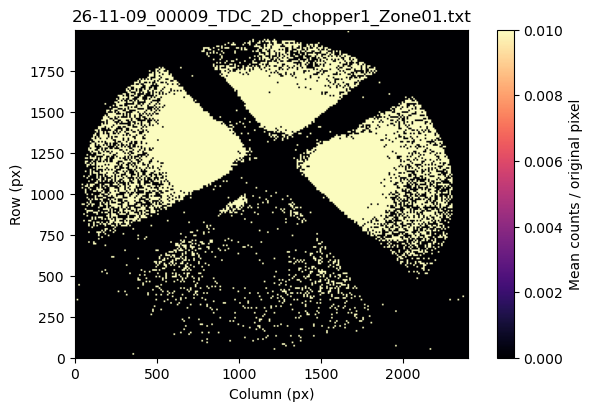

In [13]:
# 4. Preview sparse counts as block means, with a colorbar
b = 10
shown = image.reshape(height // b, b, width // b, b).mean(axis=(1, 3))
positive = shown[shown > 0]
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
artist = ax.imshow(shown, origin="lower", cmap="magma", vmin=0,
                   vmax=np.percentile(positive, upper_percentile) if positive.size else 1,
                   extent=(-0.5, width - 0.5, -0.5, height - 0.5))
ax.set(title=filename, xlabel="Column (px)", ylabel="Row (px)")
fig.colorbar(artist, ax=ax, label="Mean counts / original pixel")
plt.show()

In [16]:
# 5. Save the unbinned PNG for Paint and a separate preview with colorbar
output_folder.mkdir(parents=True, exist_ok=True)
plt.imsave(output_path, image, cmap="magma", origin="lower", vmin=0, vmax=1)
fig.savefig(output_folder / "mask_template_scan09_preview.png", dpi=180)
# Open mask_template_scan09.png in Paint. Cover excluded regions RED.
# Save a NEW file: output/mcp/beamstop_mask_scan09.png, without resizing.
# In the comparison notebook, set mask_path to that painted file.
print("Paint this file:", output_path.resolve())

Paint this file: /Users/riccardo/Github/SEXTANTS_261105/output/mcp/mask_template_scan09.png
